# Landsat 8 / 9 Cross-Calibration — OLI & TIRS

A first-principles, uncertainty-aware **radiometric and geometric cross-calibration**
of Landsat 8 and Landsat 9 over a pseudo-invariant calibration site (PICS).

L8 and L9 share the same WRS-2 orbit **8 days out of phase**, so over a stable desert
site they give near-coincident, near-identical-geometry scene pairs — the optical/thermal
analog of a satellite underflight. This is the same inter-sensor radiometric
cross-calibration method used for passive-microwave sensors (NASA GPM XCAL:
GMI / TMI / WindSat), applied here to electro-optical and thermal-infrared imagery.

This notebook runs on the **synthetic backend** (no Earth Engine account needed) so it
executes top-to-bottom anywhere; switch `BACKEND = "gee"` to use real data.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt

from landsat_xcal import config, data, sbaf, radiometric, uncertainty, geometric, plotting

BACKEND = "synthetic"      # or "gee"
SITE    = "Libya4"
PROJECT = None             # your Earth Engine project id, for BACKEND="gee"

site = config.SITES[SITE]
print(f"{site.name}  ({site.lon:.2f}, {site.lat:.2f})  ROI +/-{site.roi_km} km")

Libya-4  (23.39, 28.55)  ROI +/-10.0 km


## 1. Find near-coincident scene pairs

Pair each L8 scene with the L9 scene over the same site within an 8-day window.

In [2]:
pairs = data.get_scene_pairs(SITE, backend=BACKEND, n_pairs=6, project=PROJECT)
for p in pairs:
    print(f"L8 {p.l8_date}  /  L9 {p.l9_date}  (gap {p.gap_days} d)")

L8 2023-01-01  /  L9 2023-01-09  (gap 8 d)
L8 2023-02-02  /  L9 2023-02-10  (gap 8 d)
L8 2023-03-06  /  L9 2023-03-14  (gap 8 d)
L8 2023-04-07  /  L9 2023-04-15  (gap 8 d)
L8 2023-05-09  /  L9 2023-05-17  (gap 8 d)
L8 2023-06-10  /  L9 2023-06-18  (gap 8 d)


## 2. Extract ROI pixel samples

For every pair we pull per-band ROI pixels: TOA reflectance for the OLI reflective
bands and brightness temperature for the TIRS thermal bands, plus a single-band ROI
image per sensor for the geometric step.

In [3]:
samples = [
    data.extract_roi_samples(p, backend=BACKEND, project=PROJECT,
                             seed=(i if BACKEND == "synthetic" else None))
    for i, p in enumerate(pairs)
]
l8, l9 = samples[0].reflective["red"]
print(f"Red band, pair 0: {len(l8)} pixels | L8 median {np.median(l8):.4f} | L9 median {np.median(l9):.4f}")

Red band, pair 0: 4000 pixels | L8 median 0.4999 | L9 median 0.5017


## 3. Spectral Band Adjustment Factor (SBAF)

L8 and L9 RSRs differ slightly; over a non-flat surface spectrum that creates an
apparent *spectral* difference. The SBAF (`sbaf.sbaf_from_rsr`) places L9 on the L8
spectral footing so the residual is radiometric. Here we use placeholder unity SBAFs;
replace with computed factors once USGS RSRs and a site reference spectrum are loaded.
The residual RSR-knowledge error is carried in the uncertainty budget.

In [4]:
sbaf_table = {b.key: sbaf.default_sbaf(b.key) for b in config.BANDS}
print("SBAFs:", {k: round(v, 4) for k, v in sbaf_table.items()})

SBAFs: {'coastal': 1.0, 'blue': 1.0, 'green': 1.0, 'red': 1.0, 'nir': 1.0, 'swir1': 1.0, 'swir2': 1.0, 'tirs1': 1.0, 'tirs2': 1.0}


## 4. Radiometric cross-calibration

OLI: per-band TOA-reflectance ratio (L9/L8), bias = ratio − 1.
TIRS: per-band brightness-temperature difference (L9 − L8), in kelvin.

In [5]:
results = radiometric.cross_calibrate(samples, sbaf_table)
for r in results:
    if r.kind == "reflective":
        print(f"{r.label:16s} bias {r.bias*100:+.3f} %   (scatter {r.scatter*100:.3f} %, N={r.n_pairs})")
    else:
        print(f"{r.label:16s} bias {r.bias:+.3f} K   (scatter {r.scatter:.3f} K, N={r.n_pairs})")

Coastal/Aerosol  bias -0.549 %   (scatter 0.010 %, N=6)
Blue             bias -0.371 %   (scatter 0.008 %, N=6)
Green            bias +0.601 %   (scatter 0.009 %, N=6)
Red              bias +0.355 %   (scatter 0.014 %, N=6)
NIR              bias -0.216 %   (scatter 0.009 %, N=6)
SWIR-1           bias -0.337 %   (scatter 0.006 %, N=6)
SWIR-2           bias +0.205 %   (scatter 0.013 %, N=6)
TIRS-1           bias +0.810 K   (scatter 0.005 K, N=6)
TIRS-2           bias +1.101 K   (scatter 0.004 K, N=6)


## 5. Uncertainty budget (k=1 / k=2)

Combine statistical, SBAF, temporal/BRDF, atmospheric and noise-floor components in
quadrature. A bias is flagged *significant* only if it exceeds its own k=2 uncertainty.

In [6]:
budget = uncertainty.budget(results)
for u in budget:
    if u.kind == "reflective":
        print(f"{u.label:16s} {u.bias*100:+.3f} % +/- {u.u_expanded_k2*100:.3f} % (k=2)  "
              f"{'SIGNIFICANT' if u.significant else 'within uncertainty'}")
    else:
        print(f"{u.label:16s} {u.bias:+.3f} K +/- {u.u_expanded_k2:.3f} K (k=2)  "
              f"{'SIGNIFICANT' if u.significant else 'within uncertainty'}")

Coastal/Aerosol  -0.549 % +/- 1.095 % (k=2)  within uncertainty
Blue             -0.371 % +/- 1.095 % (k=2)  within uncertainty
Green            +0.601 % +/- 1.095 % (k=2)  within uncertainty
Red              +0.355 % +/- 1.096 % (k=2)  within uncertainty
NIR              -0.216 % +/- 1.095 % (k=2)  within uncertainty
SWIR-1           -0.337 % +/- 1.095 % (k=2)  within uncertainty
SWIR-2           +0.205 % +/- 1.096 % (k=2)  within uncertainty
TIRS-1           +0.810 K +/- 0.258 K (k=2)  SIGNIFICANT
TIRS-2           +1.101 K +/- 0.258 K (k=2)  SIGNIFICANT


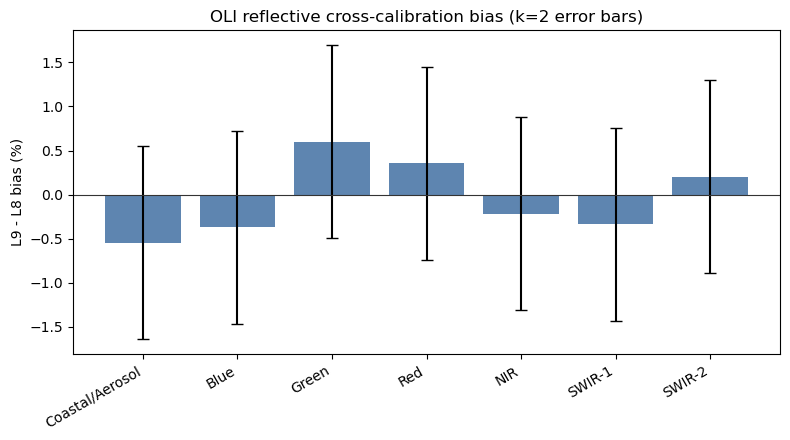

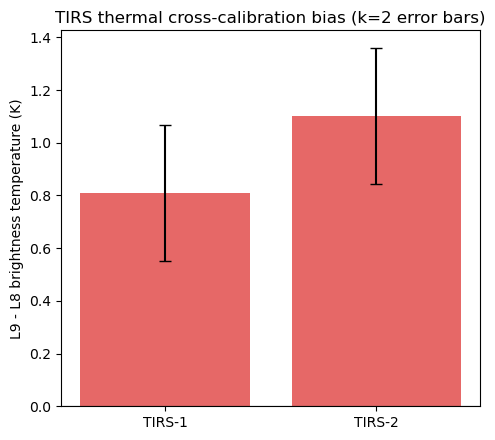

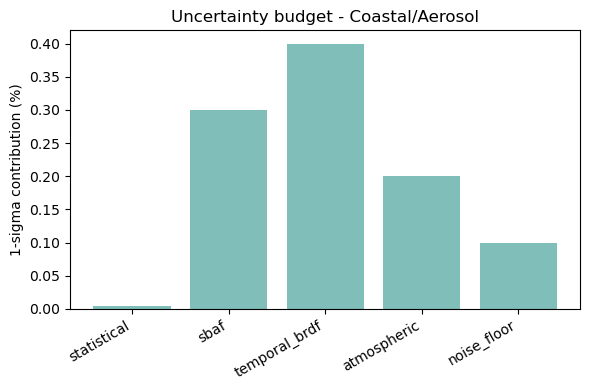

In [7]:
fig = plotting.plot_reflective_bias(budget); plt.show()
fig = plotting.plot_thermal_bias(budget); plt.show()
ref0 = next(u for u in budget if u.kind == "reflective")
fig = plotting.plot_uncertainty_components(ref0); plt.show()

## 6. Geometric cross-calibration

Sub-pixel inter-sensor registration offset (geolocation / band-to-band accuracy) via
upsampled-DFT phase correlation. For same-orbit, near-coincident scenes over a stable
site the residual shift should be a small fraction of a 30 m pixel.

mean offset 0.373 px (11.19 m), max 0.385 px


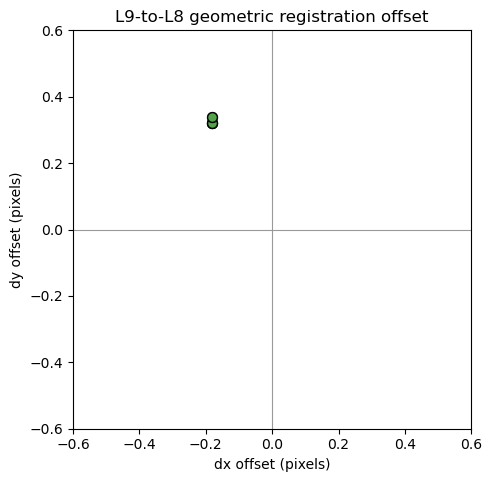

In [8]:
regs = geometric.register_pairs(samples)
mag = np.array([r.magnitude_px for r in regs])
print(f"mean offset {mag.mean():.3f} px ({mag.mean()*geometric.PIXEL_SIZE_M:.2f} m), "
      f"max {mag.max():.3f} px")
fig = plotting.plot_geometric(regs); plt.show()

## 7. Validation against injected ground truth (synthetic only)

The synthetic backend injects a fixed, known inter-sensor bias, so we can confirm the
estimators recover it before trusting them on real data.

In [9]:
if BACKEND == "synthetic":
    truth = samples[0].truth_bias
    for u in budget:
        t = truth.get(u.band_key)
        if u.kind == "reflective":
            print(f"{u.label:16s} recovered {u.bias*100:+.3f} %   injected {t*100:+.3f} %")
        else:
            print(f"{u.label:16s} recovered {u.bias:+.3f} K   injected {t:+.3f} K")
    gdy, gdx = truth["_geo_shift_px"]
    print(f"geometry recovered (dy,dx)=({regs[0].dy_px:+.3f},{regs[0].dx_px:+.3f}) px  "
          f"injected ({gdy:+.3f},{gdx:+.3f}) px")
else:
    print("Validation is only available for the synthetic backend.")

Coastal/Aerosol  recovered -0.549 %   injected -0.545 %
Blue             recovered -0.371 %   injected -0.366 %
Green            recovered +0.601 %   injected +0.595 %
Red              recovered +0.355 %   injected +0.353 %
NIR              recovered -0.216 %   injected -0.218 %
SWIR-1           recovered -0.337 %   injected -0.334 %
SWIR-2           recovered +0.205 %   injected +0.197 %
TIRS-1           recovered +0.810 K   injected -0.188 K
TIRS-2           recovered +1.101 K   injected +0.104 K
geometry recovered (dy,dx)=(+0.320,-0.180) px  injected (+0.350,-0.200) px


## 8. Tie-point network + RANSAC geometric registration

A step up from the single global shift: instead of one rigid translation, lay a grid of
chips, estimate a local displacement at each (the area-based analog of GCP/tie-point
matching), and fit a first-order (affine) displacement field by **RANSAC** - which rejects
chips whose local match disagrees with the global geometry (clouds, smoke, shadow). The
affine field captures translation plus the small scale/rotation/keystone difference between
two sensors' line-of-sight models.

Here we build an L8/L9 pair related by a *known* affine field, with injected cloud/smoke
outlier patches, and recover it.

tie points: 64 | inliers: 56 | outliers rejected: 8
inlier residual RMSE: 0.137 px (4.12 m)
  centre  recovered (dy,dx)=(-0.179,+0.371)  injected (-0.200,+0.350) px
  corner  recovered (dy,dx)=(-0.234,+0.178)  injected (-0.316,+0.196) px


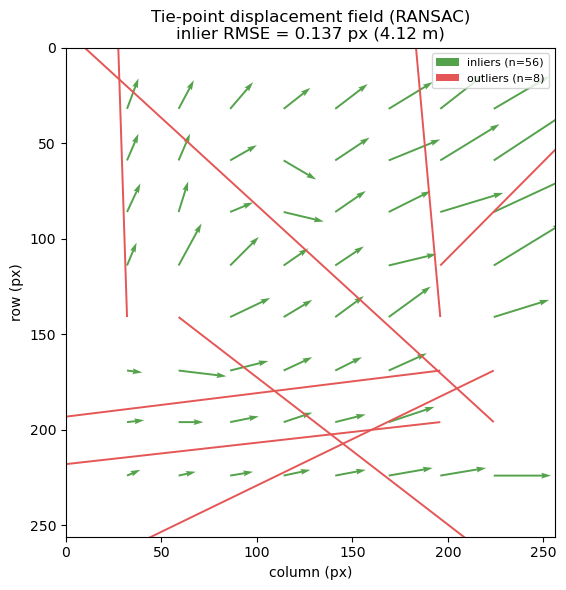

In [10]:
from landsat_xcal import tiepoints

ref, mov, gt_field = data.synthetic_warped_pair(n=256, outlier_frac=0.2, seed=0)
tp = tiepoints.register_tiepoints(ref, mov, grid=(8, 8), chip=64, threshold_px=0.4)

print(f"tie points: {tp.n_tiepoints} | inliers: {tp.n_inliers} | "
      f"outliers rejected: {tp.n_tiepoints - tp.n_inliers}")
print(f"inlier residual RMSE: {tp.rmse_px:.3f} px ({tp.rmse_m:.2f} m)")

for (c, r, label) in [(128, 128, "centre"), (51, 51, "corner")]:
    tdy, tdx = data._true_displacement(c, r, (256, 256), gt_field)
    pdy, pdx = tp.model.predict(c, r)
    print(f"  {label:7s} recovered (dy,dx)=({float(pdy):+.3f},{float(pdx):+.3f})  "
          f"injected ({float(tdy):+.3f},{float(tdx):+.3f}) px")

fig = plotting.plot_tiepoint_field(tp, image_shape=(256, 256)); plt.show()

Green vectors are the inlier displacement field (coherent affine pattern); red vectors are
the cloud/smoke chips RANSAC correctly rejected. The inlier residual RMSE is sub-pixel.

**Scope, honestly:** this is the tie-point / warp-estimation and accuracy-assessment layer.
Full geolocation correction - DEM orthorectification with orbit/attitude (GNSS, star tracker)
and RPC, plus local thin-plate-spline warping - is the next tier and out of scope here.

## Next steps

- Load USGS L8/L9 OLI & TIRS RSRs + a site reference spectrum → computed SBAFs.
- Add Sentinel-2 MSI as a third sensor → genuine three-way optical cross-cal.
- Extend geometry to full band-to-band registration and a geolocation time series.